# FDA Drug Screening for MIRI — Scoring, Filtering & Ranking

**Scoring methods:**
1. WCS + RGES — gene-set-based connectivity scoring
2. Zhang Score (ssCMap) — rank-based, preserves expression magnitude
3. Pathway-Level RGES — mechanistic pathway-reversal profiling (40 pathways: 20 UP + 20 DOWN)

**Reference gene sets:**
- `MIRI_up-down.json` — union of 78 UP + 36 DOWN L1000 genes from 3 species
- `MIRI_rank.json` — 107 GSE160516 genes with signed ranks by |disease logFC|
- `MIRI_pathways.json` — 40 MIRI KEGG/GO pathways (20 UP + 20 DOWN), 20 literature-supported

**Workflow:**
1. **Cell 1** — All imports + definitions (run once, all chart cells depend on it)
2. **Cell 2–4** — Scoring → Filtering → Ranking → CSV output
3. **Cell 5+** — Charts (each reads from saved CSVs; only Cell 1 prerequisite)

**All figures are auto-saved to `plots/` as PNGs.** Also rendered inline.


In [1]:
# ═══════════════════════════════════════════════════════════════════════
# CELL 1 — Setup: imports, paths, config, plotting defaults
# ═══════════════════════════════════════════════════════════════════════
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy.stats import spearmanr, gaussian_kde

# Project paths
PROJECT_DIR = Path("/home/chang/arc/fda_miri_scores")
sys.path.insert(0, str(PROJECT_DIR / "scripts"))
SCORES_DIR = PROJECT_DIR / "scores"
PLOTS_DIR  = PROJECT_DIR / "plots"

# Scoring functions
from utils import load_drug_deg, load_gene_set, load_rank_reference, load_pathway_gene_sets
from score_wcs_rges import score_all_wcs_rges
from score_zhang import score_all_zhang
from score_pathway_rges import score_all_pathways

# Input paths
DEG_CSV   = PROJECT_DIR / "xpert_fda-cm_deg.csv"
GENE_SET  = PROJECT_DIR / "reference-genesets" / "MIRI_up-down.json"
RANK_REF  = PROJECT_DIR / "reference-genesets" / "MIRI_rank.json"
PATHWAYS  = PROJECT_DIR / "reference-genesets" / "MIRI_pathways.json"
USE_ZSCORE = True

# Critical pathway names (loaded once, used by chart cells)
with open(PATHWAYS) as f:
    _pw_meta = json.load(f)
CRITICAL_NAMES = [p["name"] for p in _pw_meta["pathways"] if p.get("critical")]
UP_PW_NAMES    = [p["name"] for p in _pw_meta["pathways"] if p["direction"] == "UP"]
DOWN_PW_NAMES  = [p["name"] for p in _pw_meta["pathways"] if p["direction"] == "DOWN"]

# Short display names for critical pathways (used by heatmaps)
CRITICAL_SHORT = {
    "KEGG-Apoptosis": "Apoptosis",
    "GO-Cellular Response To Oxidative Stress": "Oxid. Stress",
    "KEGG-Necroptosis": "Necroptosis",
    "GO-Regulation Of Cell Death": "Cell Death Reg.",
    "KEGG-Calcium signaling pathway": "Ca Signaling",
    "GO-Mitochondrial Gene Expression": "Mito. Gene",
}

# CSV output paths (used by processing cells, read by chart cells)
ALL_SCORES_CSV   = SCORES_DIR / "fda_all_scores.csv"
FILTERED_CSV     = SCORES_DIR / "fda_filtered_scores.csv"
SCREENED_CSV     = SCORES_DIR / "fda_screened.csv"
WCS_RGES_CSV     = SCORES_DIR / "scores_wcs_rges.csv"
ZHANG_CSV        = SCORES_DIR / "scores_zhang.csv"
PATHWAY_CSV      = SCORES_DIR / "scores_pathway_rges.csv"

# Plotting defaults
%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook", palette="muted")
plt.rcParams.update({
    "figure.dpi": 120, "figure.figsize": (10, 6),
    "font.size": 11, "axes.titlesize": 14, "axes.labelsize": 12,
})

print(f"Project dir: {PROJECT_DIR}")
print(f"Scores dir:  {SCORES_DIR}")
print(f"Critical pathways: {len(CRITICAL_NAMES)} ({', '.join(CRITICAL_SHORT.values())})")
print("✓ Setup complete — ready for scoring or charting.")

Project dir: /home/chang/arc/fda_miri_scores
Scores dir:  /home/chang/arc/fda_miri_scores/scores
Critical pathways: 6 (Apoptosis, Oxid. Stress, Necroptosis, Cell Death Reg., Ca Signaling, Mito. Gene)
✓ Setup complete — ready for scoring or charting.


## 1. Scoring Pipeline

Run all 3 methods → merge → save `fda_all_scores.csv` (3127 drugs).

In [2]:
# ═══════════════════════════════════════════════════════════════════════
# CELL 2 — Scoring: WCS+RGES, Zhang, Pathway RGES → fda_all_scores.csv
# ═══════════════════════════════════════════════════════════════════════

# Score 1: WCS + RGES
print("=" * 60)
print("SCORE 1: WCS + RGES (gene-set based)")
print("=" * 60)
wcs_scores = score_all_wcs_rges(
    deg_csv_path=DEG_CSV, gene_set_path=GENE_SET, weight=1.0,
    output_path=WCS_RGES_CSV, zscore=USE_ZSCORE,
)

# Score 2: Zhang Score (Type B: ranked reference)
print("\n" + "=" * 60)
print("SCORE 2: Zhang Score (rank-based, Type B)")
print("=" * 60)
zhang_scores = score_all_zhang(
    deg_csv_path=DEG_CSV, gene_set_path=None, rank_ref_path=RANK_REF,
    output_path=ZHANG_CSV, zscore=USE_ZSCORE,
)

# Score 3: Pathway-Level RGES
print("\n" + "=" * 60)
print("SCORE 3: Pathway-Level RGES")
print("=" * 60)
pw_scores = score_all_pathways(
    deg_csv_path=DEG_CSV, pathways_json_path=PATHWAYS, weight=1.0,
    output_path=PATHWAY_CSV, zscore=USE_ZSCORE,
)

# Ensure critical pathway Z-score columns exist in pw_scores
critical_zs_cols = [f"{n}_efficacy_zs" for n in CRITICAL_NAMES]
for name in CRITICAL_NAMES:
    col = f"{name}_efficacy"
    zs_col = f"{name}_efficacy_zs"
    if zs_col not in pw_scores.columns:
        mu = pw_scores[col].mean()
        sigma = pw_scores[col].std()
        pw_scores[zs_col] = (pw_scores[col] - mu) / sigma if sigma > 1e-10 else 0.0

# Merge all scores on drug_name
all_scores = wcs_scores.merge(
    zhang_scores[["drug_name", "Zhang_c", "Zhang_p_approx", "Zhang_zs", "rank_Zhang"]],
    on="drug_name", how="inner"
).merge(
    pw_scores[["drug_name", "total_efficacy", "mean_efficacy", "n_pathways",
               "n_effective", "pathway_reversal", "pathway_reversal_zs", "rank_pathway"]
             + critical_zs_cols],
    on="drug_name", how="inner"
)

# Save merged all-drug CSV (chart cells read from this)
all_scores.to_csv(ALL_SCORES_CSV, index=False)

N_DRUGS = len(all_scores)
print(f"\n✓ Merged: {N_DRUGS} drugs across all 3 scoring methods")
print(f"  Saved to: {ALL_SCORES_CSV}")
print(f"  WCS:               [{all_scores['WCS'].min():+.4f}, {all_scores['WCS'].max():+.4f}]")
print(f"  RGES:              [{all_scores['RGES'].min():+.4f}, {all_scores['RGES'].max():+.4f}]")
print(f"  Zhang_c:           [{all_scores['Zhang_c'].min():+.4f}, {all_scores['Zhang_c'].max():+.4f}]")
print(f"  pathway_reversal:  [{all_scores['pathway_reversal'].min():.3f}, {all_scores['pathway_reversal'].max():.3f}]")


SCORE 1: WCS + RGES (gene-set based)
Loading DEG from /home/chang/arc/fda_miri_scores/xpert_fda-cm_deg.csv ...
  Applying per-gene z-score normalization...
  3127 drugs × 978 genes
Loading gene set from /home/chang/arc/fda_miri_scores/reference-genesets/MIRI_up-down.json ...
  MIRI_up-down: 78 UP, 36 DOWN (mapped to L1000)


Scoring WCS+RGES: 100%|██████████| 3127/3127 [00:00<00:00, 9841.62it/s]


Saved 3127 drugs to /home/chang/arc/fda_miri_scores/scores/scores_wcs_rges.csv

  Strong candidates (WCS < -0.2 AND RGES < -0.2): 12/3127
  Top 10:
                           drug_name       WCS      RGES  avg_rank
PEMETREXED DISODIUM HEMIPENTAHYDRATE -0.336224 -0.289719       5.0
             ERYTHROMYCIN GLUCEPTATE -0.313329 -0.306751       8.5
             PENICILLIN G BENZATHINE -0.313944 -0.273836      10.0
                ROSUVASTATIN CALCIUM -0.310353 -0.242542      15.0
                          APREPITANT -0.345559 -0.217365      15.0
                        AZITHROMYCIN -0.308870 -0.208429      25.5
                         DOXYCYCLINE -0.301613 -0.203155      31.5
             RIBOFLAVIN 5'-PHOSPHATE -0.295145 -0.205629      32.5
                   ZOLPIDEM TARTRATE -0.291000 -0.207074      32.5
                            ATENOLOL -0.298134 -0.199575      35.0

SCORE 2: Zhang Score (rank-based, Type B)
Loading DEG from /home/chang/arc/fda_miri_scores/xpert_fda-cm_deg.csv ..

Scoring Zhang (rank): 100%|██████████| 3127/3127 [00:00<00:00, 4084.90it/s]


Saved 3127 drugs to /home/chang/arc/fda_miri_scores/scores/scores_zhang.csv

  Strong candidates (Zhang c < -0.3): 162/3127
  Top 10:
                 drug_name   Zhang_c  Zhang_p_approx
      STREPTOMYCIN SULFATE -0.461936             0.0
   TENAPANOR HYDROCHLORIDE -0.460735             0.0
                 TENAPANOR -0.456742             0.0
       QUETIAPINE FUMARATE -0.450532             0.0
BRILLIANT BLUE G FREE ACID -0.434563             0.0
                  ERIBULIN -0.429611             0.0
  VANCOMYCIN HYDROCHLORIDE -0.429094             0.0
      IODIPAMIDE MEGLUMINE -0.424020             0.0
       ATRACURIUM BESYLATE -0.422975             0.0
               MIFAMURTIDE -0.422365             0.0

SCORE 3: Pathway-Level RGES
Loading DEG from /home/chang/arc/fda_miri_scores/xpert_fda-cm_deg.csv ...
  Applying per-gene z-score normalization...
  3127 drugs × 978 genes
Loading pathways from /home/chang/arc/fda_miri_scores/reference-genesets/MIRI_pathways.json ...
  MIRI_pathway

Scoring pathways: 100%|██████████| 3127/3127 [00:03<00:00, 846.86it/s]


Saved 3127 drugs to /home/chang/arc/fda_miri_scores/scores/scores_pathway_rges.csv

  Top 10 by mean pathway efficacy:
       drug_name  mean_efficacy  n_effective  pathway_reversal
        ATROPINE       0.266317           33             0.825
     PROPRANOLOL       0.261987           31             0.775
     DAPIPRAZOLE       0.255302           29             0.725
      IMIPRAMINE       0.246848           28             0.700
   OXYMETAZOLINE       0.241889           30             0.750
     NAPHAZOLINE       0.237869           30             0.750
      TAPENTADOL       0.231137           31             0.775
   ETHYLESTRENOL       0.227982           30             0.750
PROCHLORPERAZINE       0.224139           30             0.750
   MEPHENTERMINE       0.222943           28             0.700

✓ Merged: 3127 drugs across all 3 scoring methods
  Saved to: /home/chang/arc/fda_miri_scores/scores/fda_all_scores.csv
  WCS:               [-0.3718, +0.3371]
  RGES:              [-0.39

## 2. Filtering — WCS < 0 & ≥4/6 Critical Pathways Reversed

Retain drugs where:
- WCS < 0 (drug reverses disease transcriptional signature)
- ≥4 out of 6 critical pathway efficacies > 0

Output: `scores/fda_filtered_scores.csv`


In [3]:
# ═══════════════════════════════════════════════════════════════════════
# CELL 3 — Filtering: WCS<0 & ≥4/6 critical pathways > 0
# ═══════════════════════════════════════════════════════════════════════

# Read from saved CSVs
all_scores = pd.read_csv(ALL_SCORES_CSV)
pw_full    = pd.read_csv(PATHWAY_CSV)

# Ensure Z-score columns exist
for name in CRITICAL_NAMES:
    col = f"{name}_efficacy"
    zs_col = f"{name}_efficacy_zs"
    if zs_col not in pw_full.columns:
        mu = pw_full[col].mean()
        sigma = pw_full[col].std()
        pw_full[zs_col] = (pw_full[col] - mu) / sigma if sigma > 1e-10 else 0.0

# Build filters
wcs_negative = all_scores["WCS"] < 0
critical_efficacy_cols = [f"{name}_efficacy" for name in CRITICAL_NAMES]

n_critical_positive = pd.Series(0, index=pw_full.index)
print(f"Critical pathways ({len(CRITICAL_NAMES)}):")
for i, name in enumerate(CRITICAL_NAMES):
    pos = pw_full[f"{name}_efficacy"] > 0
    n_critical_positive += pos.astype(int)
    print(f"  [{i+1}] {name} > 0: {pos.sum()}/{len(pw_full)} drugs")

print(f"\n  WCS < 0:  {wcs_negative.sum()}/{len(all_scores)} drugs")
for k in range(7):
    print(f"  ≥{k} critical reversed: {(n_critical_positive >= k).sum()} drugs")

# Filter
MIN_CRITICAL = 4
critical_pass = n_critical_positive >= MIN_CRITICAL
pass_filter = wcs_negative.values & critical_pass.values
print(f"\n  WCS<0 AND ≥{MIN_CRITICAL} critical>0: {pass_filter.sum()}/{len(all_scores)} drugs")

# Build output
filtered = all_scores[pass_filter].copy()
pw_filtered = pw_full[pass_filter]
for name in CRITICAL_NAMES:
    filtered[f"{name}_efficacy"]    = pw_filtered[f"{name}_efficacy"].values
    filtered[f"{name}_efficacy_zs"] = pw_filtered[f"{name}_efficacy_zs"].values

output_cols = ["drug_name", "smiles", "drug_idx",
               "WCS", "RGES", "Zhang_c", "pathway_reversal",
               "WCS_zs", "RGES_zs", "Zhang_zs", "pathway_reversal_zs"]
output_cols += [f"{n}_efficacy" for n in CRITICAL_NAMES]
output_cols += [f"{n}_efficacy_zs" for n in CRITICAL_NAMES]

filtered_out = filtered[output_cols].copy()
filtered_out.to_csv(FILTERED_CSV, index=False)
print(f"✓ Filtered scores saved to {FILTERED_CSV}")


Critical pathways (6):
  [1] KEGG-Apoptosis > 0: 1682/3127 drugs
  [2] GO-Cellular Response To Oxidative Stress > 0: 1583/3127 drugs
  [3] KEGG-Necroptosis > 0: 1523/3127 drugs
  [4] GO-Regulation Of Cell Death > 0: 1576/3127 drugs
  [5] KEGG-Calcium signaling pathway > 0: 1349/3127 drugs
  [6] GO-Mitochondrial Gene Expression > 0: 1628/3127 drugs

  WCS < 0:  347/3127 drugs
  ≥0 critical reversed: 3127 drugs
  ≥1 critical reversed: 3103 drugs
  ≥2 critical reversed: 2728 drugs
  ≥3 critical reversed: 2067 drugs
  ≥4 critical reversed: 1113 drugs
  ≥5 critical reversed: 322 drugs
  ≥6 critical reversed: 8 drugs

  WCS<0 AND ≥4 critical>0: 199/3127 drugs
✓ Filtered scores saved to /home/chang/arc/fda_miri_scores/scores/fda_filtered_scores.csv


## 3. Ranking — Integrated Z-Score

**integrated_score = −0.3×RGES_zs − 0.1×Zhang_zs + 0.3×pathway_reversal_zs + 0.05×Σcritical_efficacy_zs**

Output: `scores/fda_screened.csv` — final ranked candidate list.


In [4]:
# ═══════════════════════════════════════════════════════════════════════
# CELL 4 — Ranking: integrated Z-score → scores/fda_screened.csv
# ═══════════════════════════════════════════════════════════════════════

filtered = pd.read_csv(FILTERED_CSV)

# Integrated score
critical_zs_sum = sum(filtered[f"{cn}_efficacy_zs"] for cn in CRITICAL_NAMES)
filtered["integrated_score"] = (
    -0.3 * filtered["RGES_zs"]
    - 0.1 * filtered["Zhang_zs"]
    + 0.3 * filtered["pathway_reversal_zs"]
    + 0.05 * critical_zs_sum
)

# Rank by integrated_score descending (higher = more therapeutic potential)
filtered["rank"] = filtered["integrated_score"].rank(ascending=False).astype(int)
screened = filtered.sort_values("rank")

screen_cols = ["drug_name", "smiles", "drug_idx",
               "WCS", "RGES", "Zhang_c", "pathway_reversal",
               "WCS_zs", "RGES_zs", "Zhang_zs", "pathway_reversal_zs",
               "integrated_score", "rank"]
screen_cols += [f"{n}_efficacy" for n in CRITICAL_NAMES]
screen_cols += [f"{n}_efficacy_zs" for n in CRITICAL_NAMES]

screened_out = screened[screen_cols].copy()
screened_out.to_csv(SCREENED_CSV, index=False)

print(f"✓ Final candidates saved to {SCREENED_CSV}")
print(f"  Candidates: {len(screened_out)}")
print(f"  integrated_score range: [{screened_out['integrated_score'].min():+.3f}, {screened_out['integrated_score'].max():+.3f}]")

# Top 20 summary
print(f"\n── Top 20 Ranked Drugs ──")
top20 = screened_out.head(20)
for i, (_, row) in enumerate(top20.iterrows()):
    print(f"  {i+1:2d}. {row['drug_name']:40s}  integrated={row['integrated_score']:+.4f}  "
          f"-RGES={-row['RGES_zs']:+.3f}  -Zhang={-row['Zhang_zs']:+.3f}  PR={row['pathway_reversal_zs']:+.3f}")

# Top 5 per-pathway detail
print(f"\n── Top 5 Drugs — Per-Pathway Efficacy ──")
for i, (_, row) in enumerate(screened_out.head(5).iterrows()):
    print(f"\n  {i+1}. {row['drug_name']}")
    for name in CRITICAL_NAMES:
        eff = row[f"{name}_efficacy"]
        zs  = row[f"{name}_efficacy_zs"]
        print(f"     {name:50s} efficacy={eff:+.4f}  zs={zs:+.3f}")


✓ Final candidates saved to /home/chang/arc/fda_miri_scores/fda_screened.csv
  Candidates: 199
  integrated_score range: [-0.795, +1.429]

── Top 20 Ranked Drugs ──
   1. TERAZOSIN                                 integrated=+1.4290  -RGES=+1.507  -Zhang=+0.973  PR=+2.603
   2. ZOLPIDEM TARTRATE                         integrated=+1.3163  -RGES=+2.350  -Zhang=+1.376  PR=+1.162
   3. CEFIDEROCOL SULFATE TOSYLATE              integrated=+1.3118  -RGES=+2.085  -Zhang=+0.672  PR=+1.402
   4. LORACARBEF                                integrated=+1.3029  -RGES=+2.154  -Zhang=+0.196  PR=+1.402
   5. ERYTHROMYCIN GLUCEPTATE                   integrated=+1.2942  -RGES=+3.611  -Zhang=+0.691  PR=-0.039
   6. DISOPYRAMIDE                              integrated=+1.2267  -RGES=+1.476  -Zhang=-0.352  PR=+2.123
   7. DIRITHROMYCIN                             integrated=+1.1307  -RGES=+2.614  -Zhang=+0.648  PR=+0.201
   8. OMEGA-3-ACID ETHYL ESTERS                 integrated=+1.0896  -RGES=+2.457  -Zha

## 4. RainCloud Plot — Z-Score Distributions

Horizontal RainCloud: half-violin (KDE) + box plot + jittered points. All scores are Z-scores — centered at 0, comparable across methods. Reads from `fda_all_scores.csv`.

Z-score ranges (should be ~mean=0, std≈1):
  WCS_zs                    [-2.984, +2.398]  μ=+0.000  σ=1.000
  RGES_zs                   [-4.702, +3.530]  μ=+0.000  σ=1.000
  Zhang_zs                  [-2.688, +2.633]  μ=-0.000  σ=1.000
  pathway_reversal_zs       [-3.162, +3.084]  μ=+0.000  σ=1.000


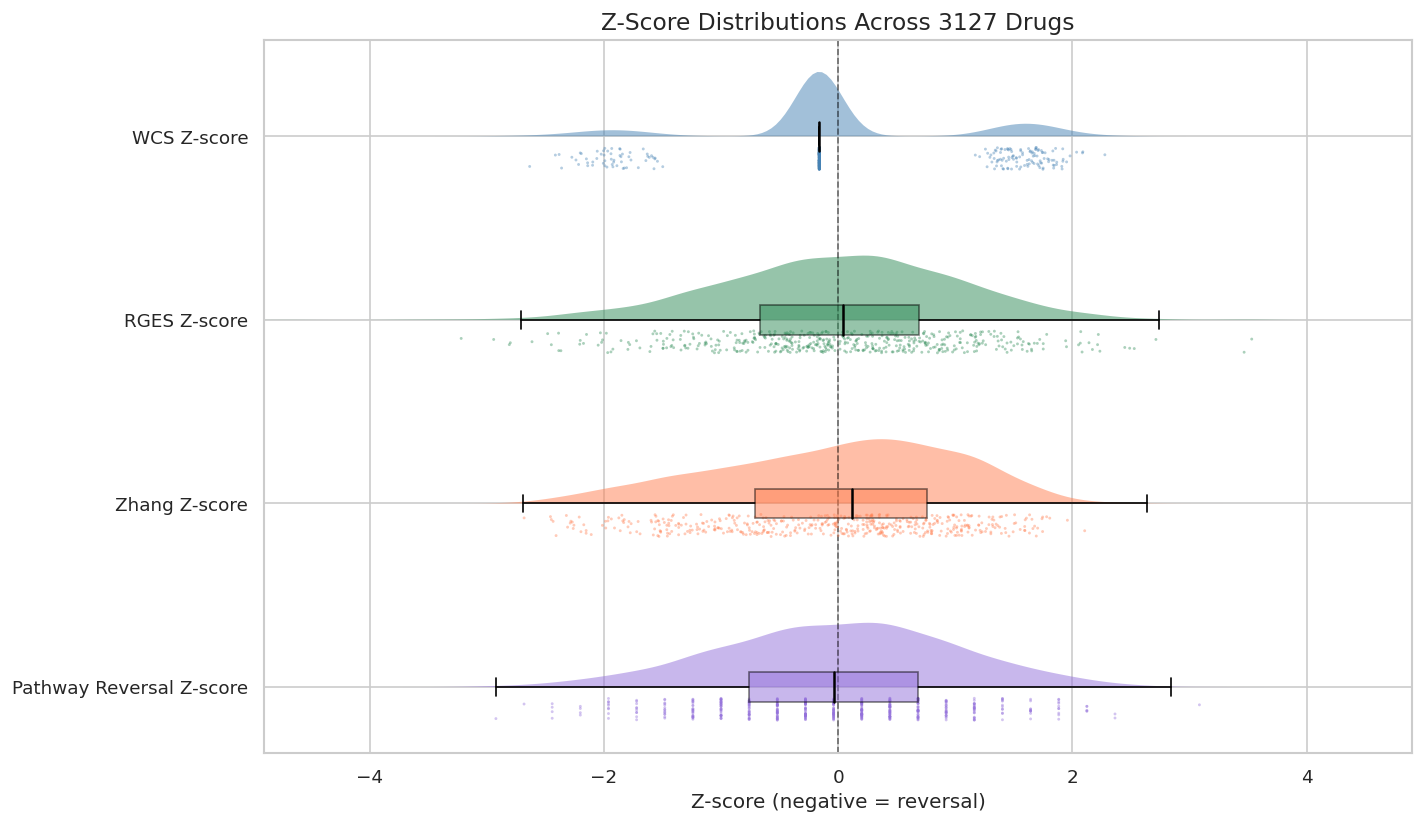

In [5]:
# ═══════════════════════════════════════════════════════════════════════
# CELL 5 — RainCloud: Z-score distributions across 4 methods
# ═══════════════════════════════════════════════════════════════════════

# Load all-drug merged scores
all_scores = pd.read_csv(ALL_SCORES_CSV)
N_DRUGS = len(all_scores)

# Build long-form DataFrame
rain_data = pd.DataFrame({
    "Score": np.concatenate([
        all_scores["WCS_zs"].values,
        all_scores["RGES_zs"].values,
        all_scores["Zhang_zs"].values,
        all_scores["pathway_reversal_zs"].values,
    ]),
    "Method": (["WCS Z-score"] * N_DRUGS + ["RGES Z-score"] * N_DRUGS +
               ["Zhang Z-score"] * N_DRUGS + ["Pathway Reversal Z-score"] * N_DRUGS),
})

print(f"Z-score ranges (should be ~mean=0, std≈1):")
for col in ["WCS_zs", "RGES_zs", "Zhang_zs", "pathway_reversal_zs"]:
    vals = all_scores[col]
    print(f"  {col:25s} [{vals.min():+.3f}, {vals.max():+.3f}]  μ={vals.mean():+.3f}  σ={vals.std():.3f}")

# ── RainCloud plot ──
# Subsample for scatter layer
rng = np.random.default_rng(42)
n_scatter = min(500, N_DRUGS)
scatter_idx = np.concatenate([
    rng.choice(np.arange(N_DRUGS), n_scatter, replace=False),
    rng.choice(np.arange(N_DRUGS, 2*N_DRUGS), n_scatter, replace=False),
    rng.choice(np.arange(2*N_DRUGS, 3*N_DRUGS), n_scatter, replace=False),
    rng.choice(np.arange(3*N_DRUGS, 4*N_DRUGS), n_scatter, replace=False),
])
rain_subset = rain_data.iloc[scatter_idx].copy()

methods_ordered = ["Pathway Reversal Z-score", "Zhang Z-score", "RGES Z-score", "WCS Z-score"]
method_colors = {
    "WCS Z-score": "steelblue",
    "RGES Z-score": "seagreen",
    "Zhang Z-score": "coral",
    "Pathway Reversal Z-score": "mediumpurple",
}

fig, ax = plt.subplots(figsize=(12, 7))
y_positions = [0, 1, 2, 3]
z_max = max(rain_data["Score"].abs().max(), 3.5)
x_lim = (-z_max - 0.2, z_max + 0.2)

# Use per-method jitter seeds so each method has its own deterministic offsets
jitter_seeds = [123, 456, 789, 101112]

for idx, method in enumerate(methods_ordered):
    full_vals = rain_data[rain_data["Method"] == method]["Score"].values
    scatter_vals = rain_subset[rain_subset["Method"] == method]["Score"].values
    y_pos = y_positions[idx]
    color = method_colors[method]

    # KDE half-violin (right)
    kde = gaussian_kde(full_vals)
    x_grid = np.linspace(x_lim[0], x_lim[1], 250)
    density = kde(x_grid)
    density_scaled = density / density.max() * 0.35
    ax.fill_between(x_grid, y_pos, y_pos + density_scaled,
                    color=color, alpha=0.5, edgecolor="none")

    # Box plot (50% alpha)
    q1, q2, q3 = np.percentile(full_vals, [25, 50, 75])
    iqr = q3 - q1
    whisker_low  = max(full_vals.min(), q1 - 1.5 * iqr)
    whisker_high = min(full_vals.max(), q3 + 1.5 * iqr)
    box_width = 0.08
    ax.add_patch(plt.Rectangle(
        (q1, y_pos - box_width), q3 - q1, 2 * box_width,
        facecolor=color, edgecolor="black", linewidth=1, alpha=0.5, zorder=5))
    ax.plot([q2, q2], [y_pos - box_width, y_pos + box_width],
            color="black", linewidth=1.5, zorder=6)
    ax.plot([whisker_low, q1], [y_pos, y_pos], color="black", linewidth=1, zorder=4)
    ax.plot([q3, whisker_high], [y_pos, y_pos], color="black", linewidth=1, zorder=4)
    for wx in [whisker_low, whisker_high]:
        ax.plot([wx, wx], [y_pos - box_width * 0.6, y_pos + box_width * 0.6],
                color="black", linewidth=1, zorder=4)

    # Jittered scatter (left) — unique seed per method
    jitter_rng = np.random.default_rng(jitter_seeds[idx])
    jitter = jitter_rng.uniform(-0.06, 0.06, len(scatter_vals))
    ax.scatter(scatter_vals, y_pos + jitter - 0.12, s=3, color=color,
               alpha=0.4, edgecolors="none", zorder=3)

ax.axvline(0, color="black", linestyle="--", linewidth=1.0, alpha=0.5)
ax.set_yticks(y_positions)
ax.set_yticklabels(methods_ordered)
ax.set_xlabel("Z-score (negative = reversal)")
ax.set_xlim(x_lim)
ax.set_title(f"Z-Score Distributions Across {N_DRUGS} Drugs", fontsize=14)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "raincloud_score-zs.png", dpi=120, bbox_inches="tight")
plt.show()

## 5. Critical Pathway Reversal RGES Distributions

Six literature-supported critical MIRI pathways. Each histogram shows per-drug efficacy across all 3127 drugs. Bin width = 2%. Reads from `scores_pathway_rges.csv`.

Critical pathways (6):
  [1] KEGG-Apoptosis (UP, 36 genes)
  [2] GO-Cellular Response To Oxidative Stress (UP, 23 genes)
  [3] KEGG-Necroptosis (UP, 24 genes)
  [4] GO-Regulation Of Cell Death (UP, 6 genes)
  [5] KEGG-Calcium signaling pathway (DOWN, 25 genes)
  [6] GO-Mitochondrial Gene Expression (DOWN, 8 genes)


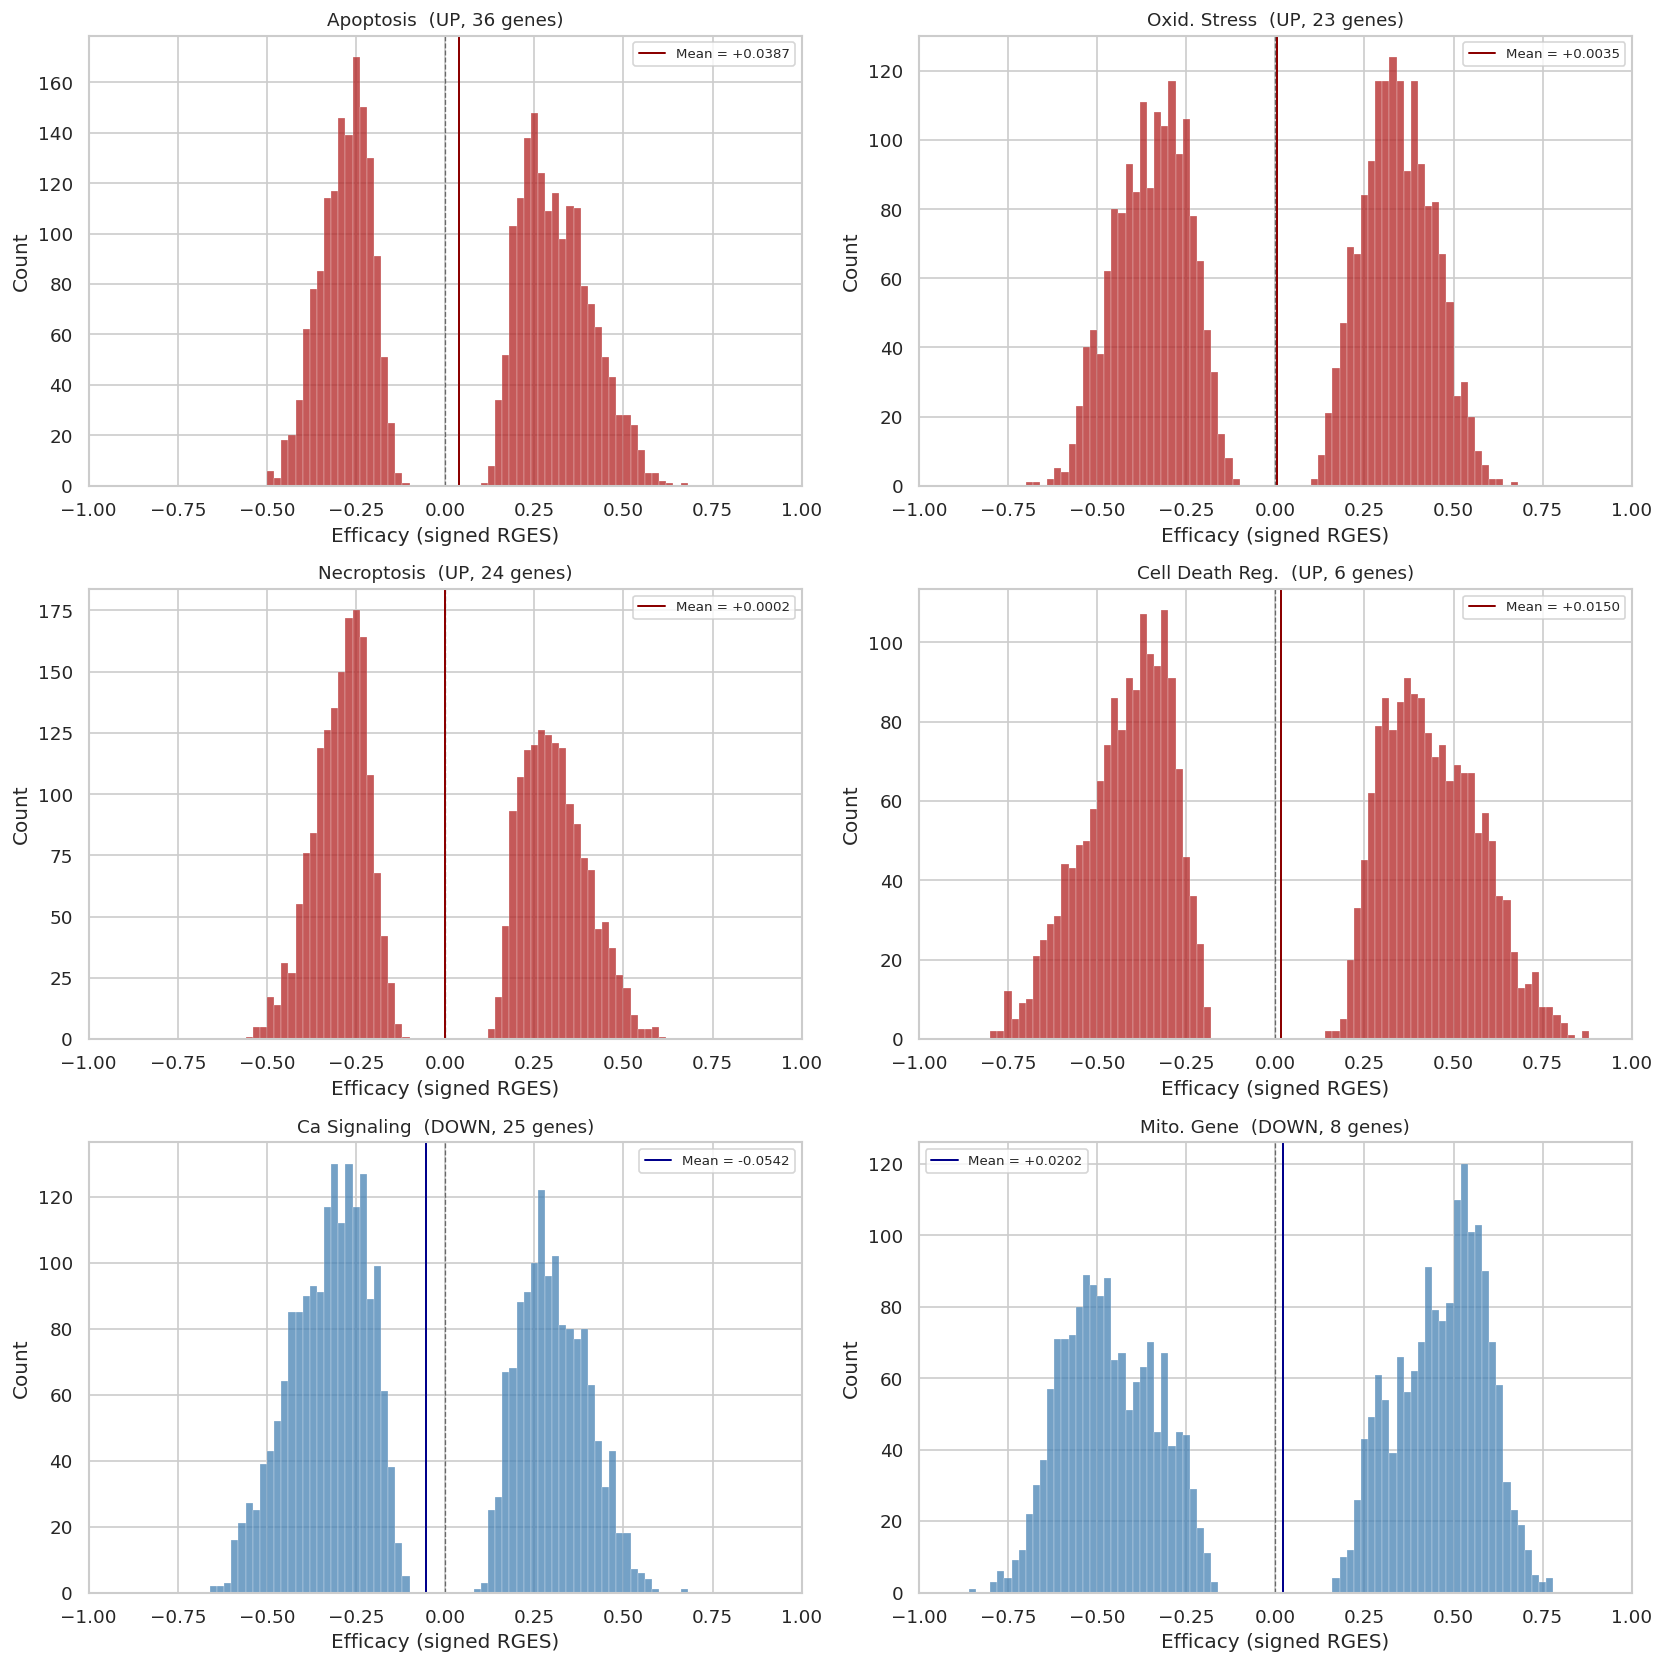

In [6]:
# ═══════════════════════════════════════════════════════════════════════
# CELL 6 — Critical Pathway efficacy histograms (3×2)
# ═══════════════════════════════════════════════════════════════════════

pw_full = pd.read_csv(PATHWAY_CSV)

print(f"Critical pathways ({len(CRITICAL_NAMES)}):")
for i, name in enumerate(CRITICAL_NAMES):
    p = next(p for p in _pw_meta["pathways"] if p["name"] == name)
    print(f"  [{i+1}] {name} ({p['direction']}, {p['n_genes']} genes)")

bins = np.arange(-1, 1 + 0.02, 0.02)
fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes_flat = axes.flatten()

for idx, name in enumerate(CRITICAL_NAMES):
    ax = axes_flat[idx]
    p = next(p for p in _pw_meta["pathways"] if p["name"] == name)
    col = f"{name}_efficacy"
    vals = pw_full[col].values
    vals_mean = vals.mean()  # compute BEFORE clipping
    color = "firebrick" if p["direction"] == "UP" else "steelblue"

    # Plot full histogram, limit x-axis display only (no data clipping)
    ax.hist(vals, bins=bins, color=color, alpha=0.75, edgecolor="white", linewidth=0.2)
    ax.axvline(0, color="black", linestyle="--", linewidth=0.8, alpha=0.5)
    ax.axvline(vals_mean, color="darkred" if p["direction"] == "UP" else "darkblue",
               linestyle="-", linewidth=1.2, label=f"Mean = {vals_mean:+.4f}")
    ax.set_xlabel("Efficacy (signed RGES)")
    ax.set_ylabel("Count")
    ax.set_xlim(-1, 1)
    ax.set_title(f"{CRITICAL_SHORT[name]}  ({p['direction']}, {p['n_genes']} genes)", fontsize=11)
    ax.legend(fontsize=8)

for idx in range(len(CRITICAL_NAMES), 6):
    axes_flat[idx].set_visible(False)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "hist_critical-pathway-efficacy.png", dpi=120, bbox_inches="tight")
plt.show()

## 6. Score Distributions (Raw Values)

2×3 histograms of raw (unnormalized) scores. Right column: per-drug per-pathway efficacy by disease direction (percentage y-axis). Reads from `fda_all_scores.csv` and `scores_pathway_rges.csv`.

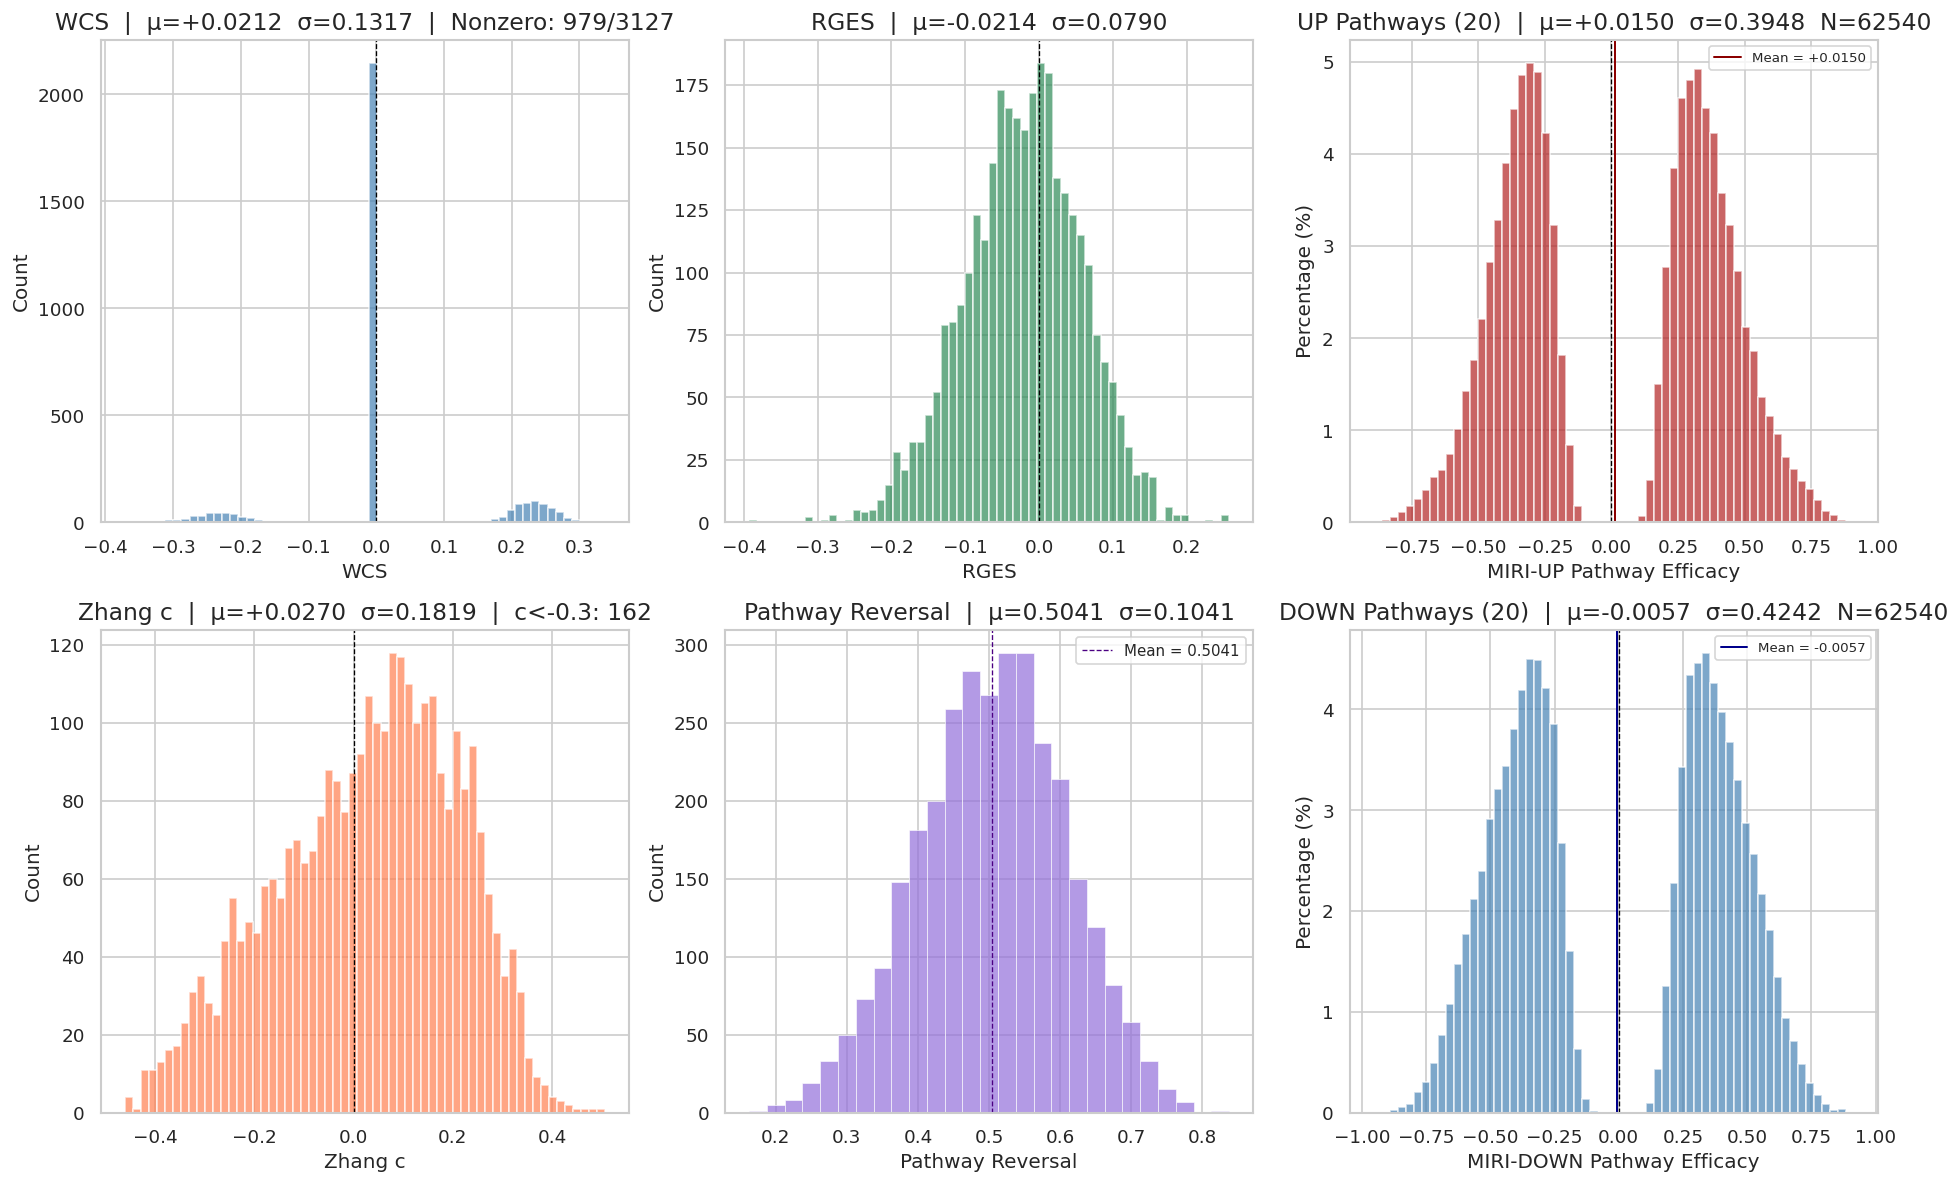

In [7]:
# ═══════════════════════════════════════════════════════════════════════
# CELL 7 — 2×3 Score Distribution Histograms
# ═══════════════════════════════════════════════════════════════════════

all_scores = pd.read_csv(ALL_SCORES_CSV)
pw_full    = pd.read_csv(PATHWAY_CSV)

# Flatten: all per-drug × per-pathway efficacy values
up_eff_cols   = [f"{n}_efficacy" for n in UP_PW_NAMES]
down_eff_cols = [f"{n}_efficacy" for n in DOWN_PW_NAMES]
all_up_eff   = pw_full[up_eff_cols].values.ravel()
all_down_eff = pw_full[down_eff_cols].values.ravel()

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# (0,0) WCS — single clean histogram, highlight non-zero fraction
ax = axes[0, 0]
wcs_vals = all_scores["WCS"].values
nonzero_wcs = wcs_vals[wcs_vals != 0]
bins_wcs = np.linspace(wcs_vals.min(), wcs_vals.max(), 60)
ax.hist(wcs_vals, bins=bins_wcs, color="steelblue", alpha=0.7)
ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax.set_xlabel("WCS"); ax.set_ylabel("Count")
ax.set_title(f"WCS  |  μ={wcs_vals.mean():+.4f}  σ={wcs_vals.std():.4f}  |  "
             f"Nonzero: {len(nonzero_wcs)}/{len(wcs_vals)}")

# (0,1) RGES
ax = axes[0, 1]
ax.hist(all_scores["RGES"], bins=60, color="seagreen", alpha=0.7)
ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax.set_xlabel("RGES"); ax.set_ylabel("Count")
ax.set_title(f"RGES  |  μ={all_scores['RGES'].mean():+.4f}  σ={all_scores['RGES'].std():.4f}")

# (0,2) UP pathway efficacy — percentage y-axis
ax = axes[0, 2]
n_up_total = len(all_up_eff)
ax.hist(all_up_eff, bins=60, color="firebrick", alpha=0.7,
        weights=np.ones(n_up_total) * 100 / n_up_total)
ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax.axvline(all_up_eff.mean(), color="darkred", linestyle="-", linewidth=1.2,
           label=f"Mean = {all_up_eff.mean():+.4f}")
ax.set_xlabel("MIRI-UP Pathway Efficacy"); ax.set_ylabel("Percentage (%)")
ax.set_title(f"UP Pathways ({len(UP_PW_NAMES)})  |  "
             f"μ={all_up_eff.mean():+.4f}  σ={all_up_eff.std():.4f}  N={n_up_total}")
ax.legend(fontsize=8)

# (1,0) Zhang c
ax = axes[1, 0]
ax.hist(all_scores["Zhang_c"], bins=60, color="coral", alpha=0.7)
ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax.set_xlabel("Zhang c"); ax.set_ylabel("Count")
strong = (all_scores["Zhang_c"] < -0.3).sum()
ax.set_title(f"Zhang c  |  μ={all_scores['Zhang_c'].mean():+.4f}  σ={all_scores['Zhang_c'].std():.4f}  |  c<-0.3: {strong}")

# (1,1) Pathway Reversal — discrete bins, no gaps
ax = axes[1, 1]
pr_vals = all_scores["pathway_reversal"].values
pr_step = 1.0 / 40
pr_bins = np.arange(pr_vals.min() - pr_step/2, pr_vals.max() + pr_step, pr_step)
ax.hist(pr_vals, bins=pr_bins, color="mediumpurple", alpha=0.7, edgecolor="white", linewidth=0.5)
ax.axvline(pr_vals.mean(), color="indigo", linestyle="--", linewidth=0.8,
           label=f"Mean = {pr_vals.mean():.4f}")
ax.set_xlabel("Pathway Reversal"); ax.set_ylabel("Count")
ax.set_title(f"Pathway Reversal  |  μ={pr_vals.mean():.4f}  σ={pr_vals.std():.4f}")
ax.legend(fontsize=9)

# (1,2) DOWN pathway efficacy — percentage y-axis
ax = axes[1, 2]
n_down_total = len(all_down_eff)
ax.hist(all_down_eff, bins=60, color="steelblue", alpha=0.7,
        weights=np.ones(n_down_total) * 100 / n_down_total)
ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax.axvline(all_down_eff.mean(), color="darkblue", linestyle="-", linewidth=1.2,
           label=f"Mean = {all_down_eff.mean():+.4f}")
ax.set_xlabel("MIRI-DOWN Pathway Efficacy"); ax.set_ylabel("Percentage (%)")
ax.set_title(f"DOWN Pathways ({len(DOWN_PW_NAMES)})  |  "
             f"μ={all_down_eff.mean():+.4f}  σ={all_down_eff.std():.4f}  N={n_down_total}")
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "hist_scores.png", dpi=120, bbox_inches="tight")
plt.show()

## 7a. Filtering — Venn Diagram

WCS < 0 ∩ Critical Pathway Reversal ≥ 4. The largest circle represents all 3127 FDA drugs; the two inner circles show which drugs pass each filter. Their overlap is the 199-drug candidate set that advances to ranking.

  All FDA drugs:        3127
  WCS < 0:              347  (only: 148)
  Critical ≥ 4:         1113  (only: 914)
  Pass (WCS<0 & Crit≥4): 199
  Neither:              1866


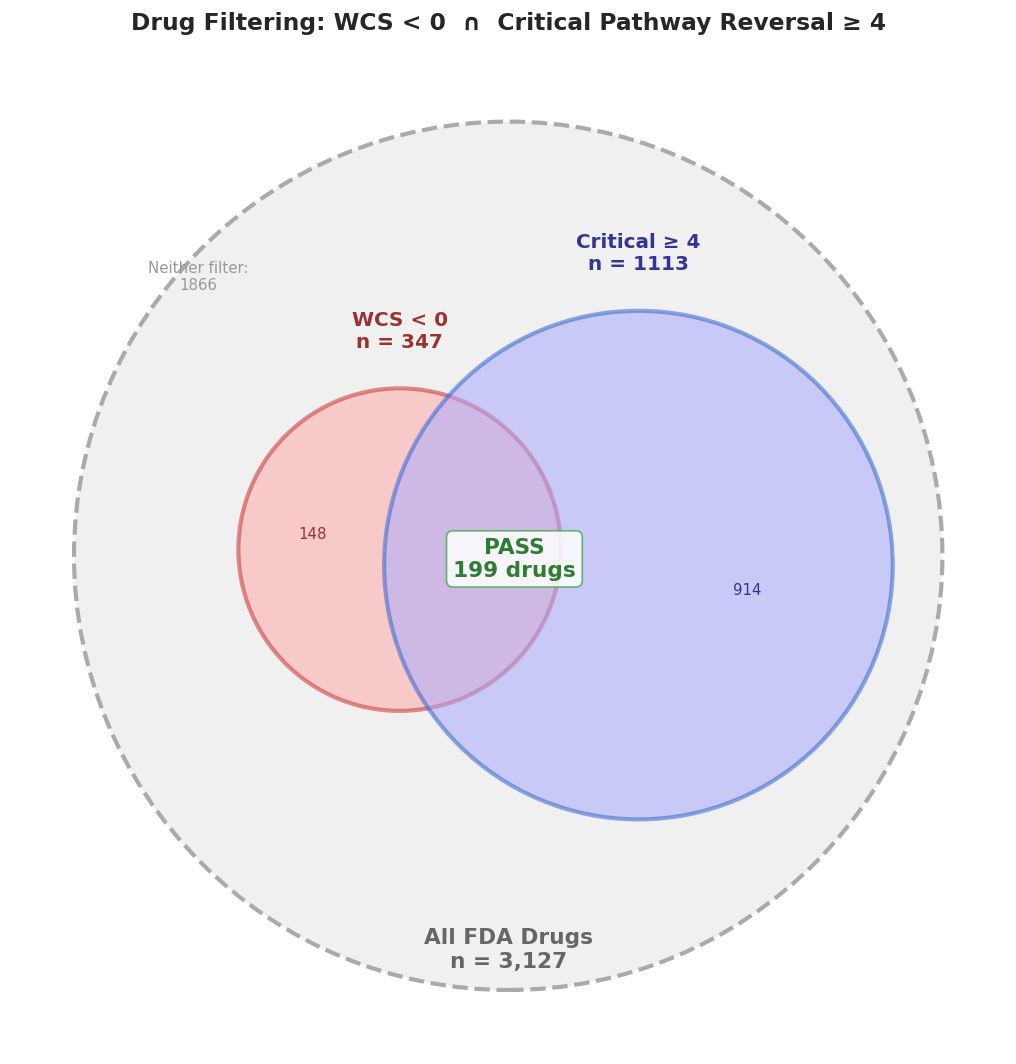

In [8]:
# ═══════════════════════════════════════════════════════════════════════
# CELL — Filtering Venn Diagram: WCS < 0 ∩ Critical ≥ 4
# ═══════════════════════════════════════════════════════════════════════
from matplotlib.patches import Circle

all_scores = pd.read_csv(ALL_SCORES_CSV)
pw_full    = pd.read_csv(PATHWAY_CSV)

# ── Compute counts ──
n_all = len(all_scores)
n_wcs = (all_scores["WCS"] < 0).sum()

n_critical_pos = pd.Series(0, index=pw_full.index)
for name in CRITICAL_NAMES:
    n_critical_pos += (pw_full[f"{name}_efficacy"] > 0).astype(int)
n_crit = (n_critical_pos >= 4).sum()

wcs_neg = all_scores["WCS"] < 0
crit_pass = n_critical_pos >= 4
n_overlap = (wcs_neg.values & crit_pass.values).sum()

n_wcs_only  = n_wcs - n_overlap
n_crit_only = n_crit - n_overlap
n_neither   = n_all - n_wcs - n_crit + n_overlap

print(f"  All FDA drugs:        {n_all}")
print(f"  WCS < 0:              {n_wcs}  (only: {n_wcs_only})")
print(f"  Critical ≥ 4:         {n_crit}  (only: {n_crit_only})")
print(f"  Pass (WCS<0 & Crit≥4): {n_overlap}")
print(f"  Neither:              {n_neither}")

# ── Draw Venn diagram ──
fig, ax = plt.subplots(figsize=(11, 9))
ax.set_xlim(-1.6, 1.6)
ax.set_ylim(-1.6, 1.6)
ax.set_aspect("equal")
ax.axis("off")

# Circle colors (matching heatmap convention)
wcs_color   = "#ffaaaa"
crit_color  = "#aaaaff"
all_color   = "#f0f0f0"
overlap_color = "#c8e6c9"

# -- Big circle: all 3127 drugs (contains both smaller circles) --
big = Circle((0, 0), 1.4, fc=all_color, ec="#aaaaaa", lw=2.5, ls="--", zorder=1)
ax.add_patch(big)
ax.text(0, -1.2, f"All FDA Drugs\nn = {n_all:,}",
        ha="center", va="top", fontsize=13, color="#666666", fontweight="bold")

# -- WCS < 0 circle --
r_wcs = 0.52
cx_wcs, cy_wcs = -0.35, 0.02
wcs_c = Circle((cx_wcs, cy_wcs), r_wcs, fc=wcs_color, ec="#cc3333", lw=2.5,
               alpha=0.55, zorder=2)
ax.add_patch(wcs_c)

# -- Critical ≥ 4 circle --
r_crit = 0.82
cx_crit, cy_crit = 0.42, -0.03
crit_c = Circle((cx_crit, cy_crit), r_crit, fc=crit_color, ec="#3366cc", lw=2.5,
                alpha=0.55, zorder=2)
ax.add_patch(crit_c)

# -- Labels --
# WCS label (above its circle)
ax.text(cx_wcs, cy_wcs + r_wcs + 0.12, f"WCS < 0\nn = {n_wcs}",
        ha="center", va="bottom", fontsize=12, fontweight="bold", color="#993333")

# Critical label (above its circle)
ax.text(cx_crit, cy_crit + r_crit + 0.12, f"Critical ≥ 4\nn = {n_crit}",
        ha="center", va="bottom", fontsize=12, fontweight="bold", color="#333399")

# Overlap label
ax.text(0.02, -0.01, f"PASS\n{n_overlap} drugs",
        ha="center", va="center", fontsize=13, fontweight="bold", color="#2e7d32",
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#4caf50", alpha=0.85))

# WCS-only label
ax.text(cx_wcs - 0.28, cy_wcs + 0.05, f"{n_wcs_only}",
        ha="center", va="center", fontsize=9, color="#993333")

# Critical-only label
ax.text(cx_crit + 0.35, cy_crit - 0.08, f"{n_crit_only}",
        ha="center", va="center", fontsize=9, color="#333399")

# Neither (inside big, outside both small)
ax.text(-1.0, 0.9, f"Neither filter:\n{n_neither}",
        ha="center", va="center", fontsize=9, color="#999999")

ax.set_title("Drug Filtering: WCS < 0  ∩  Critical Pathway Reversal ≥ 4",
             fontsize=14, fontweight="bold", pad=18)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "venn_filter.png", dpi=120, bbox_inches="tight")
plt.show()

## 7b. Filtering Heatmap

Top 30 drugs by WCS + critical pathway percentile ranks (0–100, higher = better). Green = therapeutic. Reads from `fda_filtered_scores.csv`.

  Showing top 30 of 199 filtered drugs (sorted by WCS)


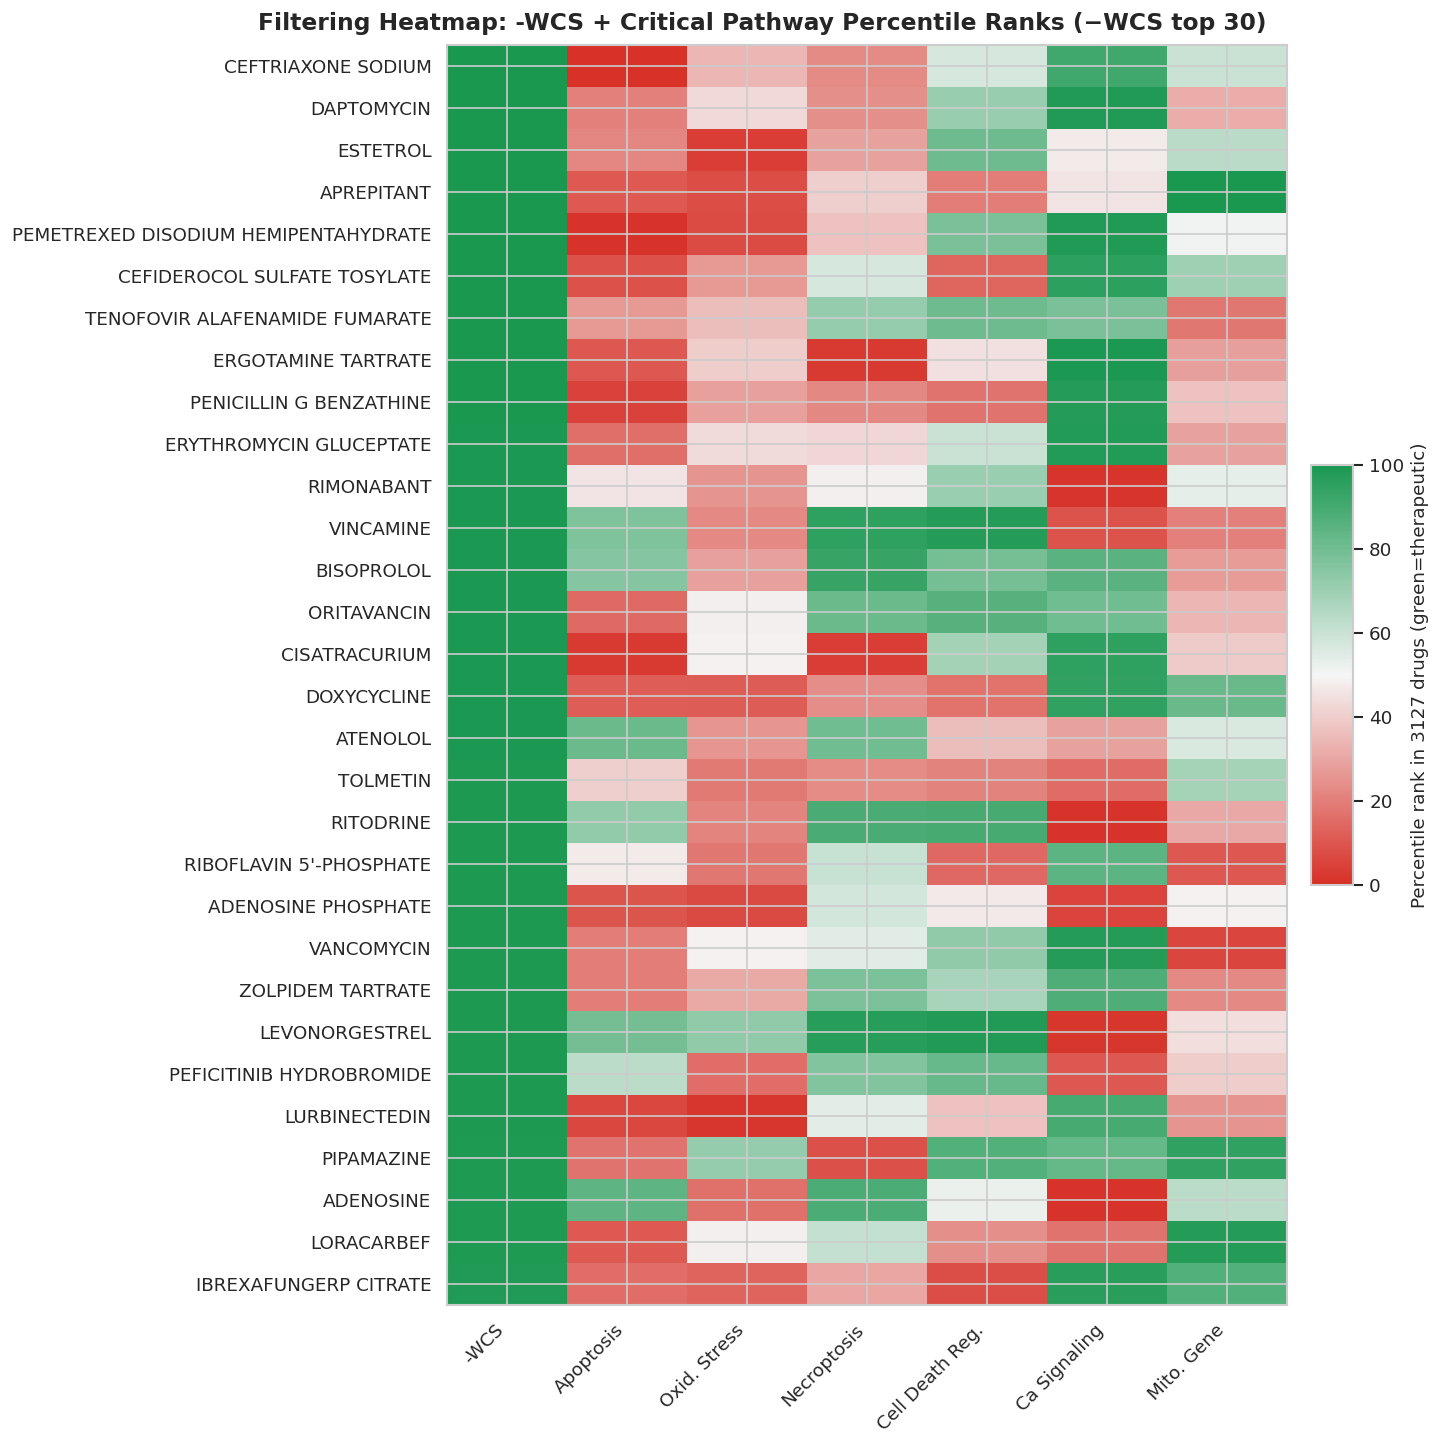

In [10]:
# ═══════════════════════════════════════════════════════════════════════
# CELL 8 — Filtering Heatmap: top 30 drugs by WCS + critical pathways
# ═══════════════════════════════════════════════════════════════════════

filtered_df = pd.read_csv(FILTERED_CSV)
pw_all = pd.read_csv(PATHWAY_CSV)
all_scores = pd.read_csv(ALL_SCORES_CSV)

# Compute percentile ranks across all 3127 drugs (higher percentile = better)
# Critical pathway efficacy percentiles
for cn in CRITICAL_NAMES:
    col = f"{cn}_efficacy"
    pw_all[f"{cn}_pct"] = pw_all[col].rank(pct=True) * 100

# -WCS percentile (negate so higher = better reversal)
all_scores["-WCS"] = -all_scores["WCS_zs"]
all_scores["-WCS_pct"] = all_scores["-WCS"].rank(pct=True) * 100

# Merge percentiles into filtered set
pct_cols = ["drug_name"] + [f"{cn}_pct" for cn in CRITICAL_NAMES]
filtered_df = filtered_df.merge(pw_all[pct_cols], on="drug_name", how="left")
filtered_df = filtered_df.merge(all_scores[["drug_name", "-WCS_pct"]], on="drug_name", how="left")

# Sort by WCS (most negative = strongest reversal) and take top 30
heat_df = filtered_df.sort_values("WCS").head(30).copy()
print(f"  Showing top {len(heat_df)} of {len(filtered_df)} filtered drugs (sorted by WCS)")

heat_cols = ["-WCS_pct"] + [f"{cn}_pct" for cn in CRITICAL_NAMES]
heat_labels = ["-WCS"] + [CRITICAL_SHORT[cn] for cn in CRITICAL_NAMES]
heat_matrix = heat_df[heat_cols].values
drug_labels = heat_df["drug_name"].values

rwg = LinearSegmentedColormap.from_list("rwg", ["#d73027", "#f5f5f5", "#1a9850"], N=256)

n_rows = len(heat_df)
n_cols = len(heat_cols)

# Layout: heatmap area h:w = 3:2
row_h = 0.35
hm_h = n_rows * row_h
hm_w = hm_h * 2 / 3

# Margins (inches)
margin_left   = 3.0    # drug names
margin_right  = 0.7    # colorbar tick labels
margin_top    = 0.55   # title spacing
margin_bottom = 0.85   # x-tick labels
gap_cbar      = 0.2    # gap between heatmap and colorbar

# Colorbar: w = 1 cell, h = 10 cells
cbar_w = row_h
cbar_h = 10 * row_h

fig_w = margin_left + hm_w + gap_cbar + cbar_w + margin_right
fig_h = margin_top + hm_h + margin_bottom

fig = plt.figure(figsize=(fig_w, fig_h))

# Heatmap axes
ax = fig.add_axes([
    margin_left / fig_w,
    margin_bottom / fig_h,
    hm_w / fig_w,
    hm_h / fig_h,
])

im = ax.imshow(heat_matrix, aspect="auto", cmap=rwg, vmin=0, vmax=100)

ax.set_xticks(range(n_cols))
ax.set_xticklabels(heat_labels, rotation=45, ha="right", fontsize=11)
ax.set_yticks(range(n_rows))
ax.set_yticklabels(drug_labels, fontsize=11)
ax.tick_params(axis="both", labelsize=11)

# Colorbar: w = 1 cell, h = 10 cells, centered vertically on heatmap
cbar_left   = margin_left + hm_w + gap_cbar
cbar_bottom = margin_bottom + (hm_h - cbar_h) / 2
cax = fig.add_axes([
    cbar_left / fig_w,
    cbar_bottom / fig_h,
    cbar_w / fig_w,
    cbar_h / fig_h,
])
cb = plt.colorbar(im, cax=cax)
cb.ax.tick_params(labelsize=11)
cb.set_label("Percentile rank in 3127 drugs (green=therapeutic)", fontsize=11)

# Title: centered on whole figure, 10px above heatmap top edge
title_y_inches = margin_bottom + hm_h + 10 / fig.dpi
fig.text(0.5, title_y_inches / fig_h,
         f"Filtering Heatmap: -WCS + Critical Pathway Percentile Ranks (−WCS top {n_rows})",
         fontsize=14, fontweight="bold", ha="center", va="bottom")

plt.savefig(PLOTS_DIR / "heatmap_filtered.png", dpi=120, bbox_inches="tight")
plt.show()

## 8. Ranking Heatmap

Top 30 drugs by integrated Z-score. All columns are percentile ranks (0–100, higher = better). Green = therapeutic. Reads from `scores/fda_screened.csv`.

  Showing top 30 of 199 ranked drugs


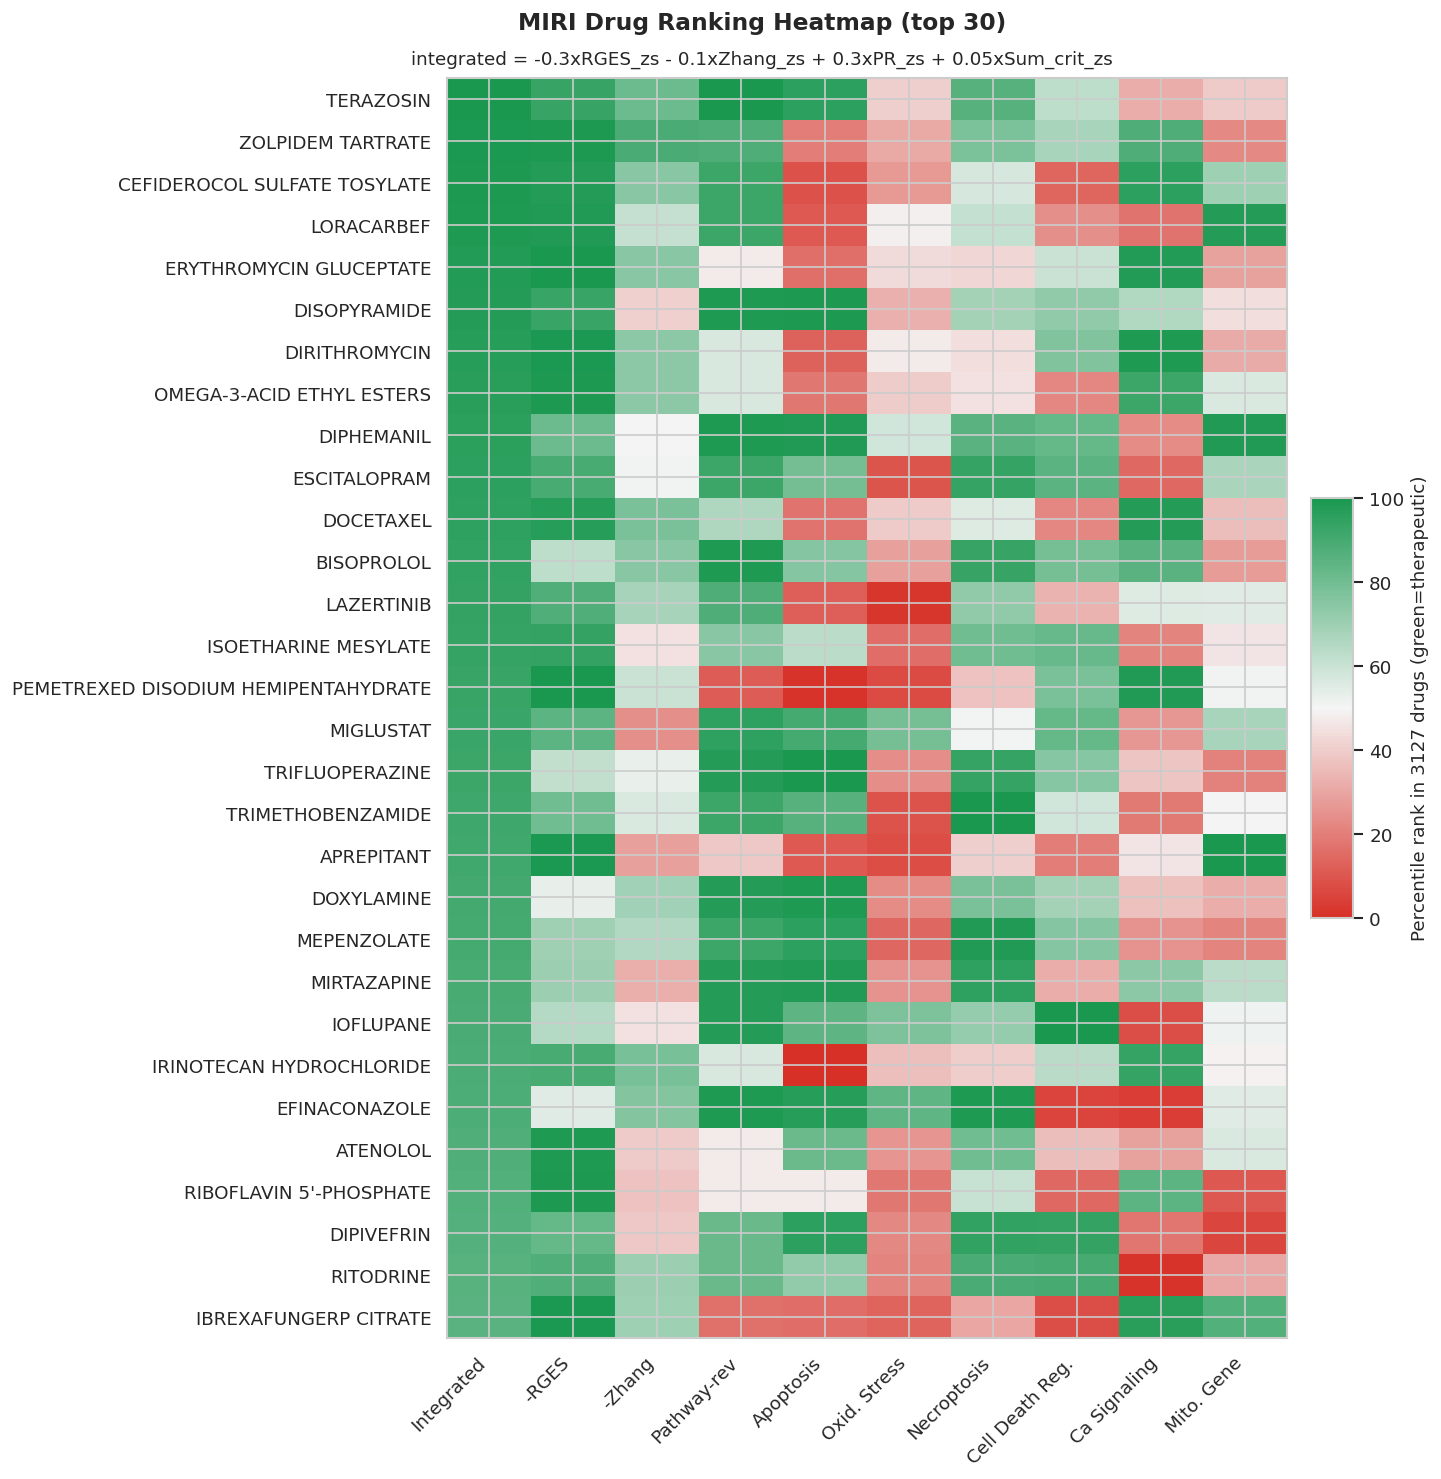

In [11]:
# ═══════════════════════════════════════════════════════════════════════
# CELL 9 — Ranking Heatmap: top 30 drugs by integrated score
# ═══════════════════════════════════════════════════════════════════════

screened_full = pd.read_csv(SCREENED_CSV)   # all 199 ranked drugs
all_scores = pd.read_csv(ALL_SCORES_CSV)     # all 3127 drugs
pw_all = pd.read_csv(PATHWAY_CSV)            # all 3127 drugs, pathway data

# Compute integrated Z-score across all 199 filtered drugs (not just top 30)
screened_full["integrated_zs"] = (
    (screened_full["integrated_score"] - screened_full["integrated_score"].mean())
    / screened_full["integrated_score"].std()
)

# Percentile ranks for scoring metrics across all 3127 drugs (higher = better)
all_scores["-RGES"] = -all_scores["RGES_zs"]
all_scores["-Zhang"] = -all_scores["Zhang_zs"]
all_scores["-RGES_pct"] = all_scores["-RGES"].rank(pct=True) * 100
all_scores["-Zhang_pct"] = all_scores["-Zhang"].rank(pct=True) * 100
all_scores["PR_pct"] = all_scores["pathway_reversal_zs"].rank(pct=True) * 100

# Percentile for integrated_score across the 199 filtered drugs
screened_full["Integrated_pct"] = screened_full["integrated_score"].rank(pct=True) * 100

# Critical pathway efficacy percentiles across all 3127 drugs
for cn in CRITICAL_NAMES:
    col = f"{cn}_efficacy"
    pw_all[f"{cn}_pct"] = pw_all[col].rank(pct=True) * 100

# Merge percentiles into screened
pct_merge = all_scores[["drug_name", "-RGES_pct", "-Zhang_pct", "PR_pct"]]
screened_full = screened_full.merge(pct_merge, on="drug_name", how="left")
pw_pct_cols = ["drug_name"] + [f"{cn}_pct" for cn in CRITICAL_NAMES]
screened_full = screened_full.merge(pw_all[pw_pct_cols], on="drug_name", how="left")

# Top 30 by rank
rank_df = screened_full.head(30).copy()
print(f"  Showing top {len(rank_df)} of {len(screened_full)} ranked drugs")

rank_cols = ["Integrated_pct", "-RGES_pct", "-Zhang_pct", "PR_pct"]
rank_cols += [f"{cn}_pct" for cn in CRITICAL_NAMES]
rank_labels = ["Integrated", "-RGES", "-Zhang", "Pathway-rev"]
rank_labels += [CRITICAL_SHORT[cn] for cn in CRITICAL_NAMES]

rank_matrix = rank_df[rank_cols].values
drug_labels = rank_df["drug_name"].values

rwg = LinearSegmentedColormap.from_list("rwg", ["#d73027", "#f5f5f5", "#1a9850"], N=256)

n_rows = len(rank_df)
n_cols = len(rank_cols)

# Layout: heatmap area h:w = 3:2
row_h = 0.35
hm_h = n_rows * row_h
hm_w = hm_h * 2 / 3

# Margins (inches)
margin_left   = 3.0    # drug names
margin_right  = 0.7    # colorbar tick labels
margin_top    = 0.55   # extra space for two-line title
margin_bottom = 0.85   # x-tick labels
gap_cbar      = 0.2    # gap between heatmap and colorbar

# Colorbar: w = 1 cell, h = 10 cells
cbar_w = row_h
cbar_h = 10 * row_h

fig_w = margin_left + hm_w + gap_cbar + cbar_w + margin_right
fig_h = margin_top + hm_h + margin_bottom

fig = plt.figure(figsize=(fig_w, fig_h))

# Heatmap axes
ax = fig.add_axes([
    margin_left / fig_w,
    margin_bottom / fig_h,
    hm_w / fig_w,
    hm_h / fig_h,
])

im = ax.imshow(rank_matrix, aspect="auto", cmap=rwg, vmin=0, vmax=100)

ax.set_xticks(range(n_cols))
ax.set_xticklabels(rank_labels, rotation=45, ha="right", fontsize=11)
ax.set_yticks(range(n_rows))
ax.set_yticklabels(drug_labels, fontsize=11)
ax.tick_params(axis="both", labelsize=11)

# Colorbar: w = 1 cell, h = 10 cells, centered vertically on heatmap
cbar_left   = margin_left + hm_w + gap_cbar
cbar_bottom = margin_bottom + (hm_h - cbar_h) / 2
cax = fig.add_axes([
    cbar_left / fig_w,
    cbar_bottom / fig_h,
    cbar_w / fig_w,
    cbar_h / fig_h,
])
cb = plt.colorbar(im, cax=cax)
cb.ax.tick_params(labelsize=11)
cb.set_label("Percentile rank in 3127 drugs (green=therapeutic)", fontsize=11)

# Title: centered on whole figure, 10px above heatmap top edge
# Two lines: main title (14px bold) + formula (11px normal)
formula_y_inches = margin_bottom + hm_h + 10 / fig.dpi
main_y_inches    = formula_y_inches + 0.28  # line spacing

fig.text(0.5, main_y_inches / fig_h,
         f"MIRI Drug Ranking Heatmap (top {n_rows})",
         fontsize=14, fontweight="bold", ha="center", va="bottom")
fig.text(0.5, formula_y_inches / fig_h,
         "integrated = -0.3xRGES_zs - 0.1xZhang_zs + 0.3xPR_zs + 0.05xSum_crit_zs",
         fontsize=11, fontweight="normal", ha="center", va="bottom")

plt.savefig(PLOTS_DIR / "heatmap_ranked.png", dpi=120, bbox_inches="tight")
plt.show()

## 9. Export Summary

Reads all CSVs and prints comprehensive pipeline summary.

In [ ]:
# ═══════════════════════════════════════════════════════════════════════
# CELL 10 — Summary: cross-method agreement, output files
# ═══════════════════════════════════════════════════════════════════════

all_scores  = pd.read_csv(ALL_SCORES_CSV)
filtered_df = pd.read_csv(FILTERED_CSV)
screened_df = pd.read_csv(SCREENED_CSV)

print("=" * 70)
print("FDA MIRI Drug Screening — Results Summary")
print("=" * 70)
print(f"\nDrugs scored:  {len(all_scores)}")
print(f"Z-score norm:   {USE_ZSCORE}")
print(f"Gene set:       {GENE_SET.name}")
print(f"Rank ref:       {RANK_REF.name}")
print(f"Pathways:       {PATHWAYS.name} ({len(UP_PW_NAMES)} UP + {len(DOWN_PW_NAMES)} DOWN, "
      f"{len(CRITICAL_NAMES)} critical)")

print(f"\n── Score Ranges (raw) ——")
for col in ["WCS", "RGES", "Zhang_c"]:
    print(f"  {col:20s} [{all_scores[col].min():+.4f}, {all_scores[col].max():+.4f}]")
print(f"  pathway_reversal:  [{all_scores['pathway_reversal'].min():.3f}, {all_scores['pathway_reversal'].max():.3f}]")

print(f"\n── Z-Score Ranges ——")
for col in ["WCS_zs", "RGES_zs", "Zhang_zs", "pathway_reversal_zs"]:
    print(f"  {col:25s} [{all_scores[col].min():+.3f}, {all_scores[col].max():+.3f}]")

# Top candidates per method
print(f"\n── Top 5 Candidates per Method ——")
print("\n  WCS + RGES (strong: WCS<-0.2 & RGES<-0.2):")
wcs_strong = all_scores[(all_scores["WCS"] < -0.2) & (all_scores["RGES"] < -0.2)]
print(f"    {len(wcs_strong)} drugs qualify")
for _, row in wcs_strong.head(5).iterrows():
    print(f"    {row['drug_name']:35s}  WCS={row['WCS']:+.4f}  RGES={row['RGES']:+.4f}")

print("\n  Zhang Score (strong: c < -0.3):")
zhang_strong = all_scores[all_scores["Zhang_c"] < -0.3].nsmallest(5, "Zhang_c")
for _, row in zhang_strong.iterrows():
    print(f"    {row['drug_name']:35s}  c={row['Zhang_c']:+.4f}  p={row['Zhang_p_approx']:.2e}")

print("\n  Pathway RGES (highest mean_efficacy):")
pw_top = all_scores.nlargest(5, "mean_efficacy")
for _, row in pw_top.iterrows():
    print(f"    {row['drug_name']:35s}  eff={row['mean_efficacy']:+.4f}  "
          f"n_eff={int(row['n_effective'])}/{int(row['n_pathways'])} ({row['pathway_reversal']:.1%})")

# Cross-method agreement
print(f"\n── Cross-Method Spearman ρ ——")
for (a, b) in [("rank_WCS", "rank_RGES"), ("rank_WCS", "rank_Zhang"),
               ("rank_RGES", "rank_Zhang"), ("rank_WCS", "rank_pathway"),
               ("rank_Zhang", "rank_pathway")]:
    rho, p = spearmanr(all_scores[a], all_scores[b])
    print(f"  {a:18s} vs {b:18s}: ρ = {rho:+.3f}  (p = {p:.1e})")

print(f"\n── Filtering Results ——")
print(f"  Filter: WCS < 0 AND ≥4/6 critical pathways efficacy > 0")
print(f"  Passed: {len(filtered_df)}/{len(all_scores)} drugs")

print(f"\n── Final Ranking ——")
print(f"  Formula: integrated = −0.3×RGES_zs − 0.1×Zhang_zs + 0.3×PR_zs + 0.05×Σcrit_zs")
print(f"  Candidates: {len(screened_df)} → {SCREENED_CSV}")

print(f"\n── Output Files ——")
for path in [WCS_RGES_CSV, ZHANG_CSV, PATHWAY_CSV, ALL_SCORES_CSV, FILTERED_CSV, SCREENED_CSV]:
    size_kb = path.stat().st_size / 1024 if path.exists() else 0
    print(f"  {str(path):60s} {size_kb:8.0f} KB")

print("\n✓ FDA MIRI drug screening pipeline complete.")